In [2]:
import sys
import os
sys.path.append(os.path.abspath('../../'))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from functions.preproc import *
from functions.ensembles import *

from sklearn import set_config
from sklearn.model_selection import train_test_split
from sklearn.model_selection import GridSearchCV
from sklearn.model_selection import RandomizedSearchCV
from sklearn.preprocessing import OrdinalEncoder
from sklearn.metrics import make_scorer
from sklearn.preprocessing import OneHotEncoder
from sklearn.model_selection import StratifiedKFold
from sksurv.metrics import integrated_brier_score
from sksurv.metrics import concordance_index_ipcw
from sksurv.nonparametric import kaplan_meier_estimator
from sklearn.inspection import permutation_importance

from sksurv.ensemble import RandomSurvivalForest
from sksurv.metrics import concordance_index_censored
from sksurv.util import Surv

import time
set_config(display="text")  # displays text representation of estimators

In [3]:
dataset = pd.read_csv("../data/data_final.csv")

diagnosis_variables = []

with open("../data/diagnosis_final.txt", "r") as file:
    for line in file:
        diagnosis_variables.append(line.strip())

treatment_variables = []
with open("../data/treatment_final.txt", "r") as file:
    for line in file:
        treatment_variables.append(line.strip())

survival_dataset = dataset.drop('Unnamed: 0', axis=1)

feature_columns = treatment_variables + diagnosis_variables

In [4]:
# Find duplicated patients
mask = (survival_dataset.duplicated(subset='PERSON_ID', keep=False)) #& (survival_dataset['Regional LN recurrence'] == 1)

# For each duplicated PERSON_ID with recurrence, keep only the row with the lowest survival days
to_remove = (
    survival_dataset[mask]
    .sort_values(['PERSON_ID', 'Survival days'], ascending=[True, True])
    .groupby('PERSON_ID')
    .head(-1)
    .index
)

survival_dataset = survival_dataset.drop(to_remove)

In [5]:
# Prepare data
data_x = survival_dataset[feature_columns]
data_y = Surv.from_arrays(
    event=survival_dataset['Regional LN recurrence'],
    time=survival_dataset['Survival days']
)

In [6]:
sgkf = StratifiedKFold(n_splits=5, shuffle=True, random_state=12)
cv = sgkf.split(X=data_x, y=survival_dataset['Regional LN recurrence'])


train_index, test_index = next(cv)
x_train = data_x.iloc[train_index]
y_train = data_y[train_index]

x_test = data_x.iloc[test_index]
y_test = data_y[test_index]

subsampling = survival_dataset.iloc[train_index].copy()

In [7]:
for train_idx, val_idx in cv:
    print("Train events:", survival_dataset.iloc[train_idx]["Regional LN recurrence"].sum())
    print("Val events:", survival_dataset.iloc[val_idx]["Regional LN recurrence"].sum())

Train events: 27.0
Val events: 6.0
Train events: 26.0
Val events: 7.0
Train events: 26.0
Val events: 7.0
Train events: 26.0
Val events: 7.0


In [8]:
# Load best hyperparameters from corrected_sub_results
best_results = pd.read_csv("../results/corrected_sub_results/rsf_subsampling_grid_search_results.csv")
# Select row with highest c-index-ipcw_mean
best_params = best_results.sort_values('c-index-ipcw_mean', ascending=False).iloc[0]

print("Best hyperparameters:")
print(f"  n_estimators: {int(best_params['n_estimators'])}")
max_depth_val = best_params['max_depth']
if pd.isna(max_depth_val):
    print(f"  max_depth: None")
else:
    print(f"  max_depth: {int(max_depth_val)}")
print(f"  max_features: {best_params['max_features']}")
print(f"  min_samples_leaf: {int(best_params['min_samples_leaf'])}")
print(f"  n_controls_per_case: {int(best_params['n_controls_per_case'])}")
print(f"  c-index-ipcw_mean (CV): {best_params['c-index-ipcw_mean']:.4f}")
print()

Best hyperparameters:
  n_estimators: 200
  max_depth: 5
  max_features: sqrt
  min_samples_leaf: 20
  n_controls_per_case: 10
  c-index-ipcw_mean (CV): 0.7235



In [9]:
# Prepare training fold dataframe (subsampling variable was created earlier)
train_fold = subsampling.copy()

# Apply case-control subsampling
x_train_sub, y_train_sub, sub_dataset = sample_case_control(
    train_fold=train_fold,
    event_col='Regional LN recurrence',
    time_col='Survival days',
    n_controls_per_case=int(best_params['n_controls_per_case']),
    feature_columns=feature_columns,
    random_state=12
)

print(f"Original training samples: {len(x_train)}")
print(f"Subsampled training samples: {len(x_train_sub)}")
print(f"Test samples: {len(x_test)}")

Original training samples: 2376
Subsampled training samples: 291
Test samples: 594


In [10]:
# Train final model with best hyperparameters
max_depth_val = best_params['max_depth']
max_depth = None if pd.isna(max_depth_val) else int(max_depth_val)

# Handle max_features - convert to proper type
max_features_val = best_params['max_features']
if isinstance(max_features_val, str):
    # Check if it's a numeric string
    try:
        max_features = float(max_features_val)
    except ValueError:
        # It's a string like 'sqrt' or 'log2'
        max_features = max_features_val
else:
    max_features = max_features_val

final_model = RandomSurvivalForest(
    n_estimators=int(best_params['n_estimators']),
    max_depth=max_depth,
    max_features=max_features,
    min_samples_leaf=int(best_params['min_samples_leaf']),
    random_state=12,
    n_jobs=-1
)

final_model.fit(x_train_sub, y_train_sub)
print("Model trained successfully!")

Model trained successfully!


In [11]:
# Test the model on test set
# Calculate c-index
c_index = final_model.score(x_test, y_test)

# Calculate c-index IPCW
tau = y_train_sub["time"].max()
c_index_ipcw = concordance_index_ipcw(y_train_sub, y_test, final_model.predict(x_test), tau=tau)[0]

# Calculate integrated Brier score
surv_funcs = final_model.predict_survival_function(x_test)

# Use robust time filtering
max_time = min(y_train_sub['time'].max(), y_test['time'].max()) * 0.9

# Use percentile-based times (5% to 90%)
times = np.percentile(y_train_sub['time'], np.linspace(5, 90, 10))
# Ensure times are unique and sorted
times = np.unique(times)
# Filter times that are within valid range
times = times[(times > 0) & (times <= max_time)]

preds_at_times = np.array([[fn(t) for t in times] for fn in surv_funcs])
brier_score = integrated_brier_score(y_train_sub, y_test, preds_at_times, times)

print("\\nTest Set Performance:")
print(f"  C-index: {c_index:.4f}")
print(f"  C-index IPCW: {c_index_ipcw:.4f}")
print(f"  Integrated Brier Score: {brier_score:.4f}")

\nTest Set Performance:
  C-index: 0.8122
  C-index IPCW: 0.7673
  Integrated Brier Score: 0.0098


# Cox-based Recalibration (Harrell Method)

In [12]:
# Step 1: Get risk scores from the RSF model trained on subsampled data
from sksurv.linear_model import CoxPHSurvivalAnalysis

# Get predictions (risk scores) from the RSF model on FULL training data
train_risk_scores = final_model.predict(x_train)

print("Risk Score Analysis:")
print(f"  Training set size: {len(train_risk_scores)}")
print(f"  Risk score range: [{train_risk_scores.min():.4f}, {train_risk_scores.max():.4f}]")
print(f"  Risk score mean: {train_risk_scores.mean():.4f}")
print(f"  Risk score std: {train_risk_scores.std():.4f}")

Risk Score Analysis:
  Training set size: 2376
  Risk score range: [0.3561, 4.9553]
  Risk score mean: 1.5965
  Risk score std: 1.0299


In [13]:
# Step 2: Fit Cox model using risk scores as the single predictor on FULL training data
# This estimates the calibration slope (should be 1 if perfectly calibrated)

# Reshape risk scores to be a 2D array (required by CoxPH)
x_train_risk = train_risk_scores.reshape(-1, 1)

# Fit Cox model
cox_recal_model = CoxPHSurvivalAnalysis()
cox_recal_model.fit(x_train_risk, y_train)

# Extract calibration slope (coefficient for risk score)
calibration_slope = cox_recal_model.coef_[0]

print("\nCox-based Recalibration Results:")
print("="*60)
print(f"Calibration slope (β): {calibration_slope:.4f}")
print(f"Expected value for perfect calibration: 1.0")
print(f"Interpretation:")
if abs(calibration_slope - 1.0) < 0.1:
    print("  ✓ Model is well-calibrated (slope ≈ 1)")
elif calibration_slope < 1.0:
    print(f"  ⚠ Model predictions are too extreme (slope = {calibration_slope:.4f} < 1)")
    print("    Recalibration will shrink predictions toward the mean")
else:
    print(f"  ⚠ Model predictions are too moderate (slope = {calibration_slope:.4f} > 1)")
    print("    Recalibration will spread predictions away from the mean")
print("="*60)


Cox-based Recalibration Results:
Calibration slope (β): 1.1450
Expected value for perfect calibration: 1.0
Interpretation:
  ⚠ Model predictions are too moderate (slope = 1.1450 > 1)
    Recalibration will spread predictions away from the mean


In [14]:
# Step 3: Create prediction function for recalibrated model
def predict_survival_recalibrated_cox(rsf_model, cox_model, X, times):
    """
    Predict recalibrated survival probabilities using Cox-based recalibration.
    
    Parameters:
    -----------
    rsf_model : RandomSurvivalForest
        The original RSF model
    cox_model : CoxPHSurvivalAnalysis
        The Cox model fitted on risk scores
    X : array-like
        Test samples
    times : array-like
        Time points at which to predict survival
    
    Returns:
    --------
    survival_probs : array, shape (n_samples, n_times)
        Recalibrated survival probabilities
    """
    # Get risk scores from RSF
    risk_scores = rsf_model.predict(X).reshape(-1, 1)
    
    # Get survival functions from Cox model
    surv_funcs_recal = cox_model.predict_survival_function(risk_scores)
    
    # Evaluate at specified times
    survival_probs = np.array([[fn(t) for t in times] for fn in surv_funcs_recal])
    
    return survival_probs

print("Recalibrated prediction function created successfully!")

Recalibrated prediction function created successfully!


In [15]:
# Step 4: Evaluate recalibrated model on test set
print("="*60)
print("RECALIBRATED MODEL PERFORMANCE ON TEST SET")
print("="*60)

# Get recalibrated risk scores
test_risk_scores_recal = final_model.predict(x_test).reshape(-1, 1)
recalibrated_predictions = cox_recal_model.predict(test_risk_scores_recal)

# Calculate C-index (should remain the same as recalibration doesn't change ranking)
c_index_recal = concordance_index_censored(y_test['event'], y_test['time'], recalibrated_predictions)[0]

# Calculate C-index IPCW
tau_recal = y_train["time"].max()
c_index_ipcw_recal = concordance_index_ipcw(y_train_sub, y_test, recalibrated_predictions, tau=tau_recal)[0]

# Calculate Brier score with recalibrated predictions
max_time_recal = min(y_train['time'].max(), y_test['time'].max()) * 0.9
times_recal = np.percentile(y_train['time'], np.linspace(5, 90, 10))
times_recal = np.unique(times_recal)
times_recal = times_recal[(times_recal > 0) & (times_recal <= max_time_recal)]

# Get recalibrated survival predictions
survival_preds_recal = predict_survival_recalibrated_cox(final_model, cox_recal_model, x_test, times_recal)
brier_score_recal = integrated_brier_score(y_train, y_test, survival_preds_recal, times_recal)

print("\nRecalibrated Model Metrics:")
print(f"  C-index: {c_index_recal:.4f}")
print(f"  C-index IPCW: {c_index_ipcw_recal:.4f}")
print(f"  Integrated Brier Score: {brier_score_recal:.4f}")

print("\nOriginal Model (subsampled) Metrics:")
print(f"  C-index: {c_index:.4f}")
print(f"  C-index IPCW: {c_index_ipcw:.4f}")
print(f"  Integrated Brier Score: {brier_score:.4f}")

print("\nImprovement:")
print(f"  ΔC-index: {c_index_recal - c_index:+.4f}")
print(f"  ΔC-index IPCW: {c_index_ipcw_recal - c_index_ipcw:+.4f}")
print(f"  ΔBrier Score: {brier_score_recal - brier_score:+.4f} (lower is better)")
print("="*60)

RECALIBRATED MODEL PERFORMANCE ON TEST SET

Recalibrated Model Metrics:
  C-index: 0.8122
  C-index IPCW: 0.7673
  Integrated Brier Score: 0.0078

Original Model (subsampled) Metrics:
  C-index: 0.8122
  C-index IPCW: 0.7673
  Integrated Brier Score: 0.0098

Improvement:
  ΔC-index: +0.0000
  ΔC-index IPCW: +0.0000
  ΔBrier Score: -0.0020 (lower is better)


# Gap-Based Risk Binning Analysis

Instead of using arbitrary percentiles (33/67), analyze the actual distribution of risk scores to find natural gaps that can define meaningful risk categories.

RSF RISK SCORE DISTRIBUTION ANALYSIS

Basic Statistics:
  Min: 0.001740
  Max: 0.238393
  Mean: 0.017079
  Median: 0.004597
  Std: 0.031361
  Range: 0.236653

Percentiles:
   0.00%: 0.001740 (1 samples, 0.2%)
  10.00%: 0.002225 (60 samples, 10.1%)
  20.00%: 0.002542 (119 samples, 20.0%)
  25.00%: 0.002731 (149 samples, 25.1%)
  30.00%: 0.002894 (178 samples, 30.0%)
  33.33%: 0.002991 (198 samples, 33.3%)
  40.00%: 0.003446 (238 samples, 40.1%)
  50.00%: 0.004597 (297 samples, 50.0%)
  60.00%: 0.006697 (356 samples, 59.9%)
  66.67%: 0.008733 (396 samples, 66.7%)
  70.00%: 0.010059 (416 samples, 70.0%)
  75.00%: 0.013381 (445 samples, 74.9%)
  80.00%: 0.020956 (475 samples, 80.0%)
  90.00%: 0.053582 (534 samples, 89.9%)
  100.00%: 0.238393 (594 samples, 100.0%)

Clustering Analysis:
  Unique risk scores: 585 out of 594 samples
  Diversity: 98.5%

Top 5 Largest Gaps (potential breakpoints):
  1. Gap: 0.040447 at position 98.5% (between 0.129855 and 0.170302)
  2. Gap: 0.015429 at position

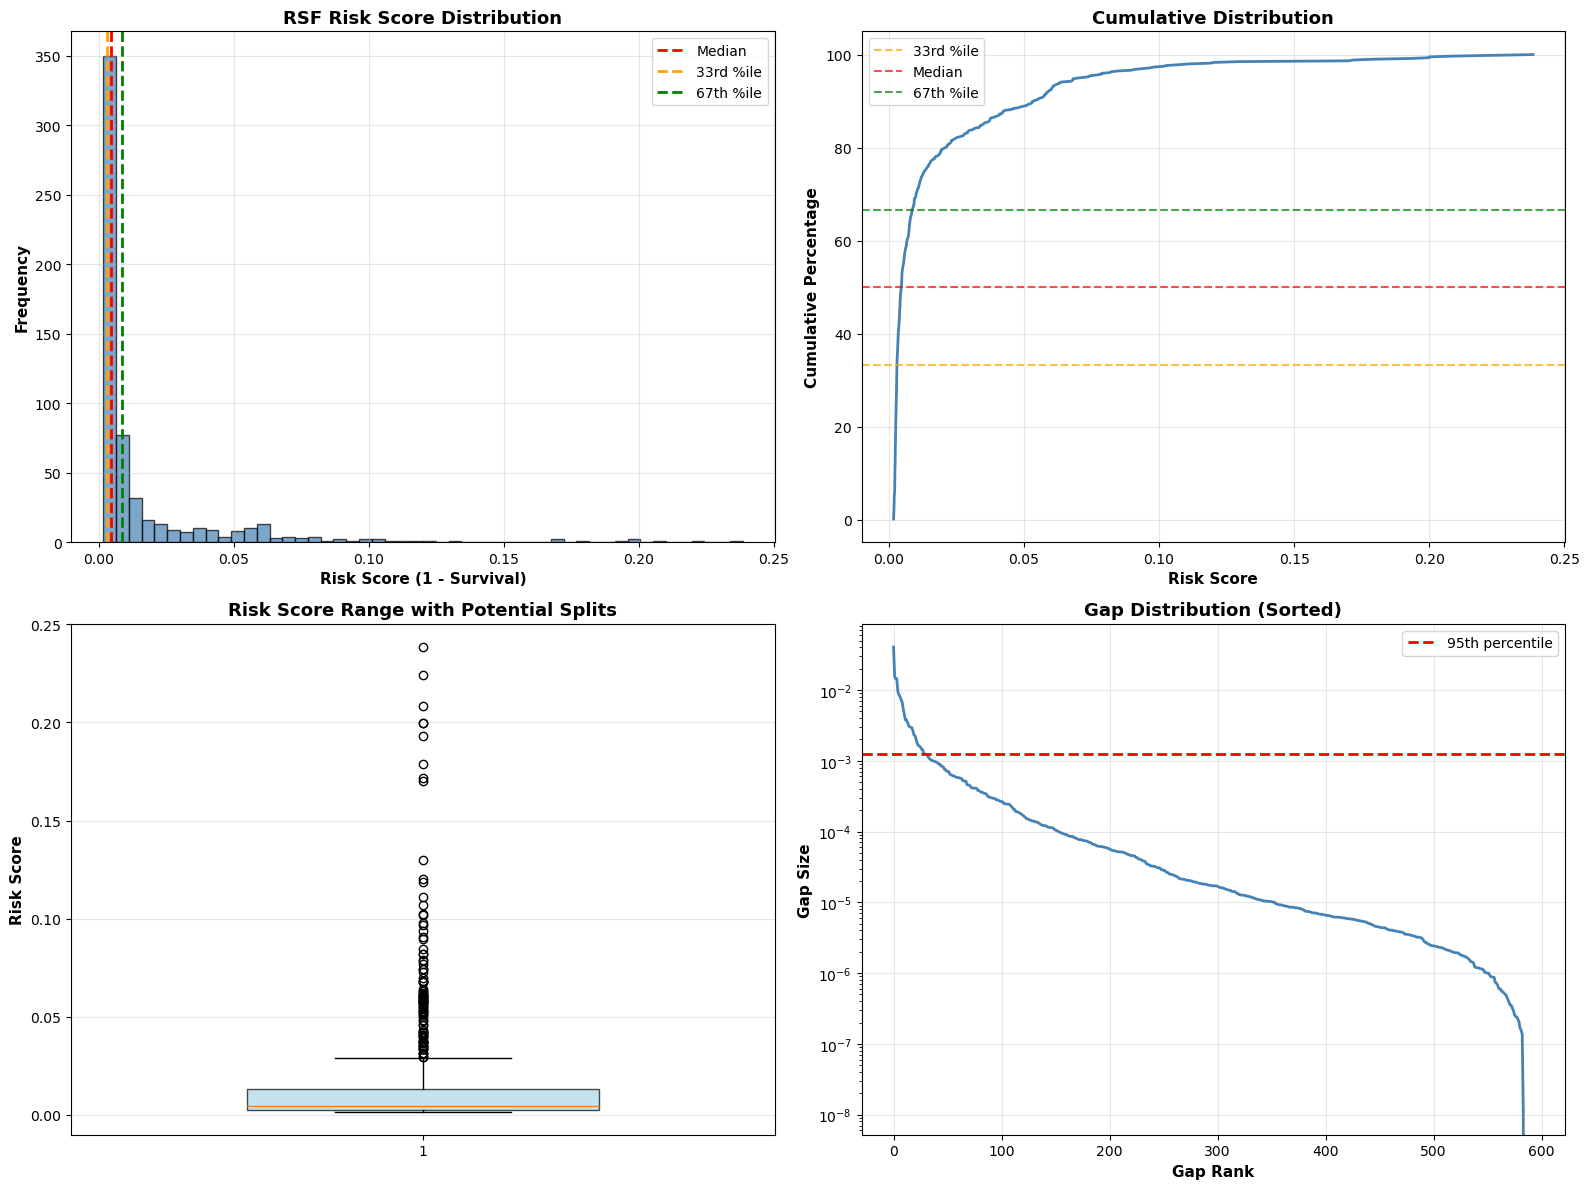

In [16]:
# Analyze risk score distribution to find optimal binning strategy for RSF
import matplotlib.pyplot as plt
import numpy as np

time_point = 1825  # 5 years
pred_surv_after_rsf = predict_survival_recalibrated_cox(final_model, cox_recal_model, x_test, np.array([time_point]))[:, 0]
risk_scores_rsf = 1 - pred_surv_after_rsf

print("="*70)
print("RSF RISK SCORE DISTRIBUTION ANALYSIS")
print("="*70)

# Basic statistics
print(f"\nBasic Statistics:")
print(f"  Min: {risk_scores_rsf.min():.6f}")
print(f"  Max: {risk_scores_rsf.max():.6f}")
print(f"  Mean: {risk_scores_rsf.mean():.6f}")
print(f"  Median: {np.median(risk_scores_rsf):.6f}")
print(f"  Std: {risk_scores_rsf.std():.6f}")
print(f"  Range: {risk_scores_rsf.max() - risk_scores_rsf.min():.6f}")

# Percentiles
print(f"\nPercentiles:")
percentiles = [0, 10, 20, 25, 30, 33.33, 40, 50, 60, 66.67, 70, 75, 80, 90, 100]
for p in percentiles:
    val = np.percentile(risk_scores_rsf, p)
    count = (risk_scores_rsf <= val).sum()
    print(f"  {p:5.2f}%: {val:.6f} ({count} samples, {count/len(risk_scores_rsf)*100:.1f}%)")

# Check for clustering
print(f"\nClustering Analysis:")
unique_vals = len(np.unique(risk_scores_rsf))
print(f"  Unique risk scores: {unique_vals} out of {len(risk_scores_rsf)} samples")
print(f"  Diversity: {unique_vals/len(risk_scores_rsf)*100:.1f}%")

# Find natural gaps
sorted_risks = np.sort(risk_scores_rsf)
gaps = np.diff(sorted_risks)
large_gaps_idx = np.argsort(gaps)[-5:][::-1]  # Top 5 largest gaps

print(f"\nTop 5 Largest Gaps (potential breakpoints):")
for i, idx in enumerate(large_gaps_idx):
    gap_size = gaps[idx]
    before_val = sorted_risks[idx]
    after_val = sorted_risks[idx + 1]
    position = (idx + 1) / len(sorted_risks) * 100
    print(f"  {i+1}. Gap: {gap_size:.6f} at position {position:.1f}% (between {before_val:.6f} and {after_val:.6f})")

# Visualization
fig, axes = plt.subplots(2, 2, figsize=(16, 12))

# 1. Histogram
axes[0, 0].hist(risk_scores_rsf, bins=50, edgecolor='black', alpha=0.7, color='steelblue')
axes[0, 0].axvline(np.median(risk_scores_rsf), color='red', linestyle='--', linewidth=2, label='Median')
axes[0, 0].axvline(np.percentile(risk_scores_rsf, 33.33), color='orange', linestyle='--', linewidth=2, label='33rd %ile')
axes[0, 0].axvline(np.percentile(risk_scores_rsf, 66.67), color='green', linestyle='--', linewidth=2, label='67th %ile')
axes[0, 0].set_xlabel('Risk Score (1 - Survival)', fontsize=11, fontweight='bold')
axes[0, 0].set_ylabel('Frequency', fontsize=11, fontweight='bold')
axes[0, 0].set_title('RSF Risk Score Distribution', fontsize=13, fontweight='bold')
axes[0, 0].legend()
axes[0, 0].grid(alpha=0.3)

# 2. Cumulative distribution
sorted_risks_plot = np.sort(risk_scores_rsf)
cumulative = np.arange(1, len(sorted_risks_plot) + 1) / len(sorted_risks_plot) * 100
axes[0, 1].plot(sorted_risks_plot, cumulative, linewidth=2, color='steelblue')
axes[0, 1].axhline(33.33, color='orange', linestyle='--', linewidth=1.5, alpha=0.7, label='33rd %ile')
axes[0, 1].axhline(50, color='red', linestyle='--', linewidth=1.5, alpha=0.7, label='Median')
axes[0, 1].axhline(66.67, color='green', linestyle='--', linewidth=1.5, alpha=0.7, label='67th %ile')
axes[0, 1].set_xlabel('Risk Score', fontsize=11, fontweight='bold')
axes[0, 1].set_ylabel('Cumulative Percentage', fontsize=11, fontweight='bold')
axes[0, 1].set_title('Cumulative Distribution', fontsize=13, fontweight='bold')
axes[0, 1].legend()
axes[0, 1].grid(alpha=0.3)

# 3. Box plot
axes[1, 0].boxplot([risk_scores_rsf], vert=True, widths=0.5, patch_artist=True,
                    boxprops=dict(facecolor='lightblue', alpha=0.7))
axes[1, 0].set_ylabel('Risk Score', fontsize=11, fontweight='bold')
axes[1, 0].set_title('Risk Score Range with Potential Splits', fontsize=13, fontweight='bold')
axes[1, 0].grid(alpha=0.3, axis='y')

# 4. Gap analysis
axes[1, 1].plot(range(len(gaps)), np.sort(gaps)[::-1], linewidth=2, color='steelblue')
axes[1, 1].axhline(np.percentile(gaps, 95), color='red', linestyle='--', linewidth=2, label='95th percentile')
axes[1, 1].set_xlabel('Gap Rank', fontsize=11, fontweight='bold')
axes[1, 1].set_ylabel('Gap Size', fontsize=11, fontweight='bold')
axes[1, 1].set_title('Gap Distribution (Sorted)', fontsize=13, fontweight='bold')
axes[1, 1].legend()
axes[1, 1].grid(alpha=0.3)
axes[1, 1].set_yscale('log')

plt.tight_layout()
plt.savefig('rsf_risk_score_distribution_analysis.png', dpi=300, bbox_inches='tight')
plt.show()

print("\n" + "="*70)

✓ RSF risk-categorized calibration plot saved!

Risk Categories (based on NATURAL GAPS in distribution):
  Low Risk: Bottom 70.0% (risk ≤ 0.0101)
    └─ n=416
  High Risk: 70.0%-90.0% (0.0101 < risk ≤ 0.0536)
    └─ n=118
  Very High Risk: Top 10.0% (risk > 0.0536)
    └─ n=60


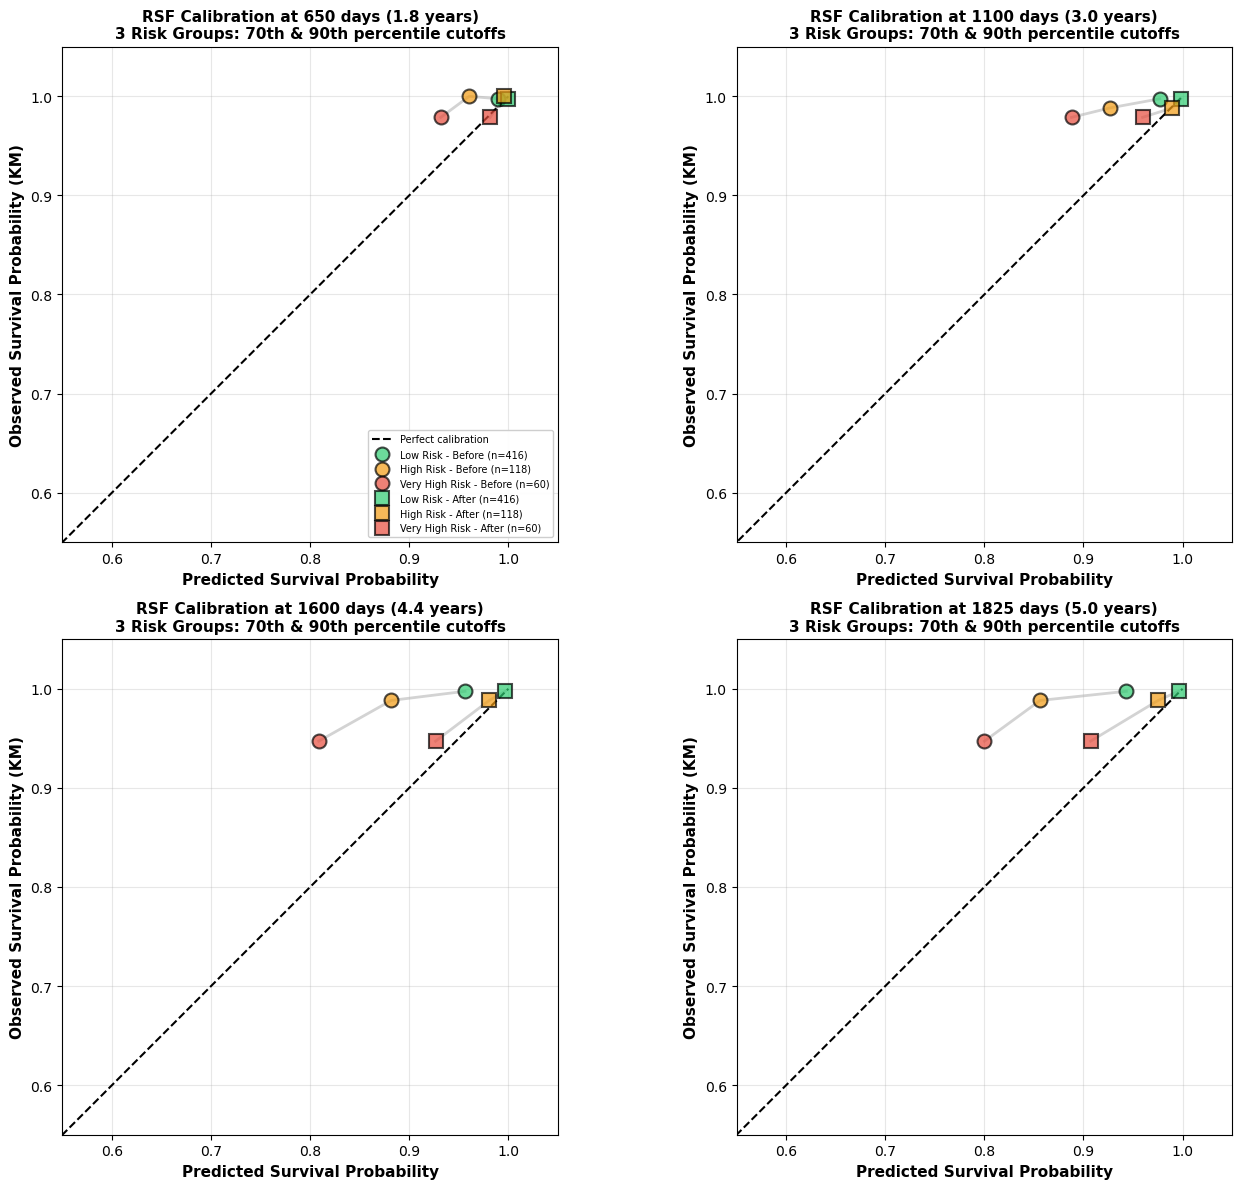

In [17]:
# GAP-BASED CALIBRATION PLOT FOR RSF
# Uses natural gaps from risk distribution analysis to define risk categories
# Run the previous cell first to identify the optimal gap positions
import matplotlib.pyplot as plt

time_points = [650, 1100, 1600, 1825]

# Get predictions
surv_funcs_before = final_model.predict_survival_function(x_test)
times_for_calib = np.array(time_points)
survival_preds_after = predict_survival_recalibrated_cox(final_model, cox_recal_model, x_test, times_for_calib)

fig, axes = plt.subplots(2, 2, figsize=(14, 12))
axes = axes.ravel()

# ADJUST THESE PERCENTILE THRESHOLDS based on the gap analysis output above
# Look at the "Top 5 Largest Gaps" to find the best positions
# Example: If largest gaps are at 70% and 90%, use [70, 90]
percentile_thresholds = [70, 90]  # MODIFY THESE based on your gap analysis results

for idx, time_point in enumerate(time_points):
    ax = axes[idx]
    
    pred_surv_before = np.array([fn(time_point) for fn in surv_funcs_before])
    pred_surv_after = survival_preds_after[:, idx]
    risk_scores = 1 - pred_surv_after
    
    # Create bins based on percentiles that align with natural gaps
    thresh_low = np.percentile(risk_scores, percentile_thresholds[0])
    thresh_high = np.percentile(risk_scores, percentile_thresholds[1])
    
    # Assign risk categories
    risk_labels = np.zeros(len(risk_scores), dtype=int)
    risk_labels[risk_scores > thresh_low] = 1   # High risk
    risk_labels[risk_scores > thresh_high] = 2  # Very high risk
    
    risk_names = ['Low Risk', 'High Risk', 'Very High Risk']
    colors_bins = ['#2ecc71', '#f39c12', '#e74c3c']  # Green, Orange, Red
    
    mean_pred_before = []
    mean_pred_after = []
    mean_observed = []
    bin_sizes = []
    
    for bin_idx in range(3):
        mask = risk_labels == bin_idx
        bin_sizes.append(mask.sum())
        
        if mask.sum() == 0:
            continue
        
        mean_pred_before.append(pred_surv_before[mask].mean())
        mean_pred_after.append(pred_surv_after[mask].mean())
        
        km_time, km_prob = kaplan_meier_estimator(
            y_test['event'][mask],
            y_test['time'][mask]
        )
        
        if time_point <= km_time.min():
            obs_surv = 1.0
        elif time_point >= km_time.max():
            obs_surv = km_prob[-1]
        else:
            obs_surv = np.interp(time_point, km_time, km_prob)
        
        mean_observed.append(obs_surv)
    
    # Plot
    ax.plot([0, 1], [0, 1], 'k--', label='Perfect calibration', linewidth=1.5)
    
    # Before recalibration - plot connecting line in light gray
    ax.plot(mean_pred_before, mean_observed, '-', 
            color='lightgray', linewidth=2, zorder=1)
    
    # After recalibration - plot connecting line in light gray
    ax.plot(mean_pred_after, mean_observed, '-', 
            color='lightgray', linewidth=2, zorder=1)
    
    # Add colored markers for each risk bin - BEFORE calibration
    for i in range(len(mean_pred_before)):
        marker_style = 'o'  # Circle for before
        label_before = f'{risk_names[i]} - Before (n={bin_sizes[i]})' if idx == 0 else None
        ax.plot([mean_pred_before[i]], [mean_observed[i]], marker_style,
                color=colors_bins[i], markersize=10, alpha=0.7,
                markeredgecolor='black', markeredgewidth=1.5,
                label=label_before, zorder=3)
    
    # Add colored markers for each risk bin - AFTER calibration
    for i in range(len(mean_pred_after)):
        marker_style = 's'  # Square for after
        label_after = f'{risk_names[i]} - After (n={bin_sizes[i]})' if idx == 0 else None
        ax.plot([mean_pred_after[i]], [mean_observed[i]], marker_style,
                color=colors_bins[i], markersize=10, alpha=0.7,
                markeredgecolor='black', markeredgewidth=1.5,
                label=label_after, zorder=3)
    
    ax.set_xlabel('Predicted Survival Probability', fontsize=11, fontweight='bold')
    ax.set_ylabel('Observed Survival Probability (KM)', fontsize=11, fontweight='bold')
    ax.set_title(f'RSF Calibration at {time_point} days ({time_point/365:.1f} years)\n3 Risk Groups: {percentile_thresholds[0]}th & {percentile_thresholds[1]}th percentile cutoffs', 
                 fontsize=11, fontweight='bold')
    if idx == 0:
        ax.legend(loc='lower right', fontsize=7, framealpha=0.95, ncol=1)
    ax.grid(True, alpha=0.3)
    ax.set_xlim(0.55, 1.05)
    ax.set_ylim(0.55, 1.05)
    ax.set_aspect('equal')

plt.tight_layout()
plt.savefig('rsf_calibration_risk_categories.png', dpi=300, bbox_inches='tight')
print("✓ RSF risk-categorized calibration plot saved!")
print(f"\nRisk Categories (based on NATURAL GAPS in distribution):")
print(f"  Low Risk: Bottom {percentile_thresholds[0]:.1f}% (risk ≤ {thresh_low:.4f})")
print(f"    └─ n={bin_sizes[0]}")
print(f"  High Risk: {percentile_thresholds[0]:.1f}%-{percentile_thresholds[1]:.1f}% ({thresh_low:.4f} < risk ≤ {thresh_high:.4f})")
print(f"    └─ n={bin_sizes[1]}")
print(f"  Very High Risk: Top {100-percentile_thresholds[1]:.1f}% (risk > {thresh_high:.4f})")
print(f"    └─ n={bin_sizes[2]}")
plt.show()


In [22]:
# Export gap-based calibration data for RSF
import pandas as pd

time_points = [650, 1100, 1600, 1825]

# Get predictions
surv_funcs_before = final_model.predict_survival_function(x_test)
times_for_calib = np.array(time_points)
survival_preds_after = predict_survival_recalibrated_cox(final_model, cox_recal_model, x_test, times_for_calib)

# Use the same percentile thresholds from the gap-based plot
percentile_thresholds = [70, 90]  # Adjust based on your gap analysis

# Store calibration data for each time point
calibration_data_gap = []

for idx, time_point in enumerate(time_points):
    pred_surv_before = np.array([fn(time_point) for fn in surv_funcs_before])
    pred_surv_after = survival_preds_after[:, idx]
    risk_scores = 1 - pred_surv_after
    
    # Create bins using gap-based thresholds
    thresh_low = np.percentile(risk_scores, percentile_thresholds[0])
    thresh_high = np.percentile(risk_scores, percentile_thresholds[1])
    
    risk_labels = np.zeros(len(risk_scores), dtype=int)
    risk_labels[risk_scores > thresh_low] = 1
    risk_labels[risk_scores > thresh_high] = 2
    
    # Calculate mean predicted and observed survival for each bin
    for bin_idx in range(3):
        mask = risk_labels == bin_idx
        
        if mask.sum() == 0:
            continue
        
        mean_before = pred_surv_before[mask].mean()
        mean_after = pred_surv_after[mask].mean()
        
        km_time, km_prob = kaplan_meier_estimator(
            y_test['event'][mask],
            y_test['time'][mask]
        )
        
        if time_point <= km_time.min():
            obs_surv = 1.0
        elif time_point >= km_time.max():
            obs_surv = km_prob[-1]
        else:
            obs_surv = np.interp(time_point, km_time, km_prob)
        
        calibration_data_gap.append({
            'time_point': time_point,
            'risk_bin': bin_idx,
            'risk_category': ['Low Risk', 'High Risk', 'Very High Risk'][bin_idx],
            'mean_pred_before': mean_before,
            'mean_pred_after': mean_after,
            'mean_observed': obs_surv,
            'bin_size': mask.sum()
        })

# Convert to DataFrame and save
calib_gap_df = pd.DataFrame(calibration_data_gap)
calib_gap_df.to_csv('rsf_calibration_data_gap_based.csv', index=False)
print("Gap-based calibration data exported to 'rsf_calibration_data_gap_based.csv'")
print(calib_gap_df)

Gap-based calibration data exported to 'rsf_calibration_data_gap_based.csv'
    time_point  risk_bin   risk_category  mean_pred_before  mean_pred_after  \
0          650         0        Low Risk          0.989662         0.999246   
1          650         1       High Risk          0.960522         0.995311   
2          650         2  Very High Risk          0.931832         0.981669   
3         1100         0        Low Risk          0.976979         0.998318   
4         1100         1       High Risk          0.926548         0.989570   
5         1100         2  Very High Risk          0.887959         0.959683   
6         1600         0        Low Risk          0.956309         0.996868   
7         1600         1       High Risk          0.881753         0.980675   
8         1600         2  Very High Risk          0.808662         0.926573   
9         1825         0        Low Risk          0.943295         0.995991   
10        1825         1       High Risk          0.856